In [1]:
from sklearn.manifold import TSNE
import numpy as np
import matplotlib.pyplot as plt
import umap
from sklearn.decomposition import PCA

/home/tim4ik/main_code_base/python_projects/Active-Learning-for-Email-Interaction-Dynamics/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
X = np.load("X/train_X.npy")

In [3]:
X

array([[0., 0., 1., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 1., 0.]], shape=(149, 130802), dtype=float32)

In [4]:
open_rates = X.mean(axis=0)
open_rates

array([0.01342282, 0.00671141, 0.06040268, ..., 0.01342282, 0.09395973,
       0.18791947], shape=(130802,), dtype=float32)

In [5]:
perplexity = [15,30,45]
tsne_list = []

for p in perplexity:
    tsne = TSNE(perplexity= p ,n_components=2, random_state=42, n_jobs=2)

    tsne.fit(X.T)

    tsne_list.append(tsne)

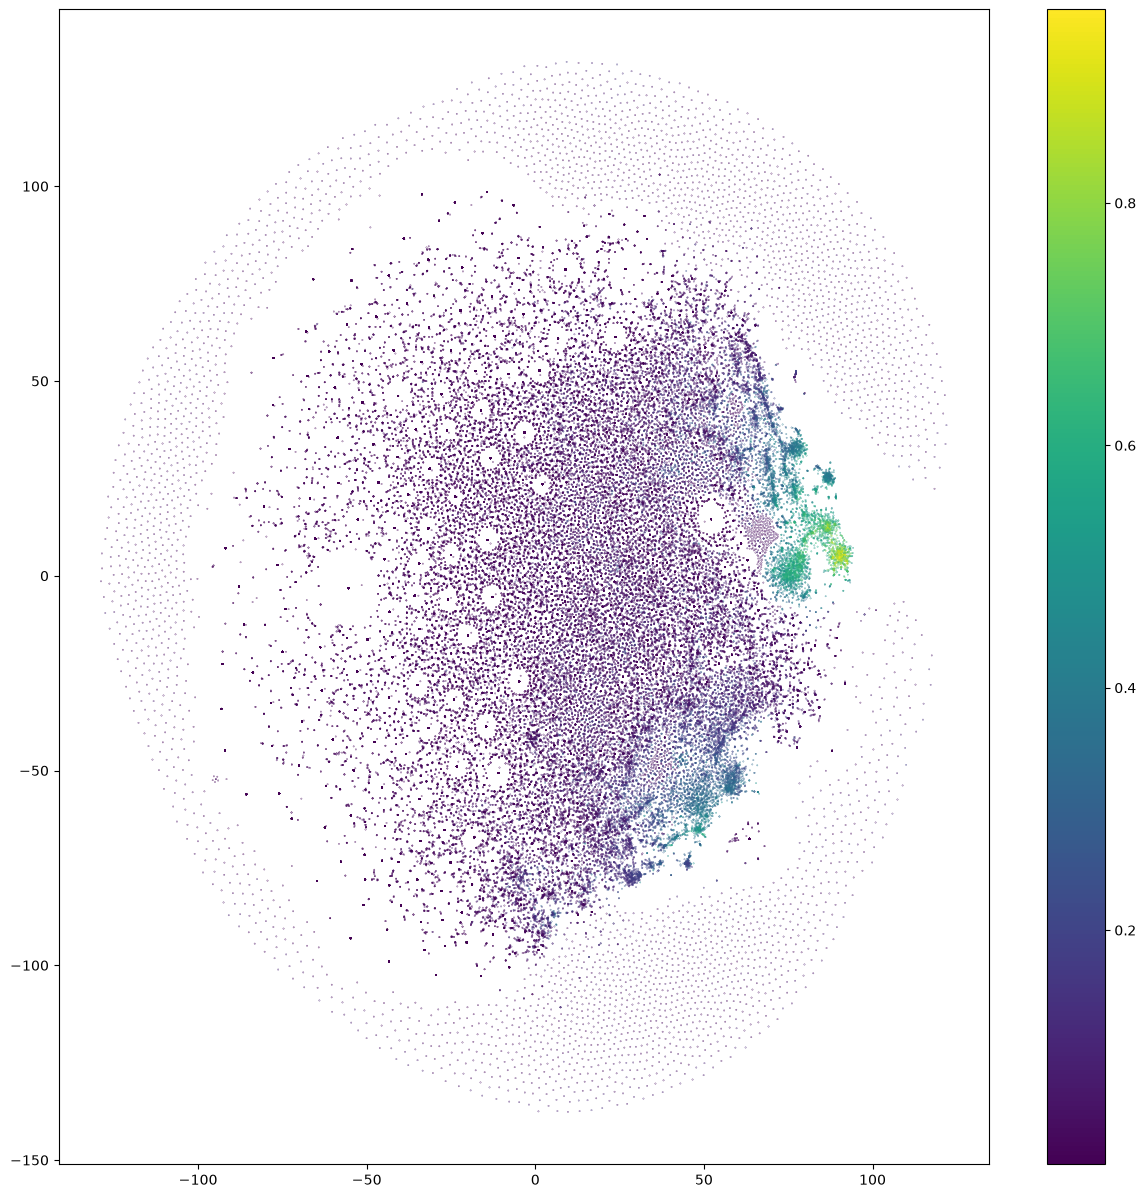

In [6]:
plt.figure(figsize=(15,15))

x_tsne_embed = tsne_list[0].embedding_
plt.scatter(x_tsne_embed[:, 0], x_tsne_embed[:, 1], c = open_rates,s=0.05)
plt.colorbar()
plt.show()

In [4]:
tsne  = TSNE(n_components=2, random_state=42, n_jobs=2)

In [8]:
user_proj = tsne.fit_transform(X.T)

In [10]:
user_proj

array([[ -1.8820771, -15.650875 ],
       [-70.565475 , -58.442463 ],
       [ 20.87832  ,  41.440594 ],
       ...,
       [ -9.387001 , -80.261246 ],
       [  7.6158934, -81.36902  ],
       [  1.2952086, -81.46801  ]], shape=(130802, 2), dtype=float32)

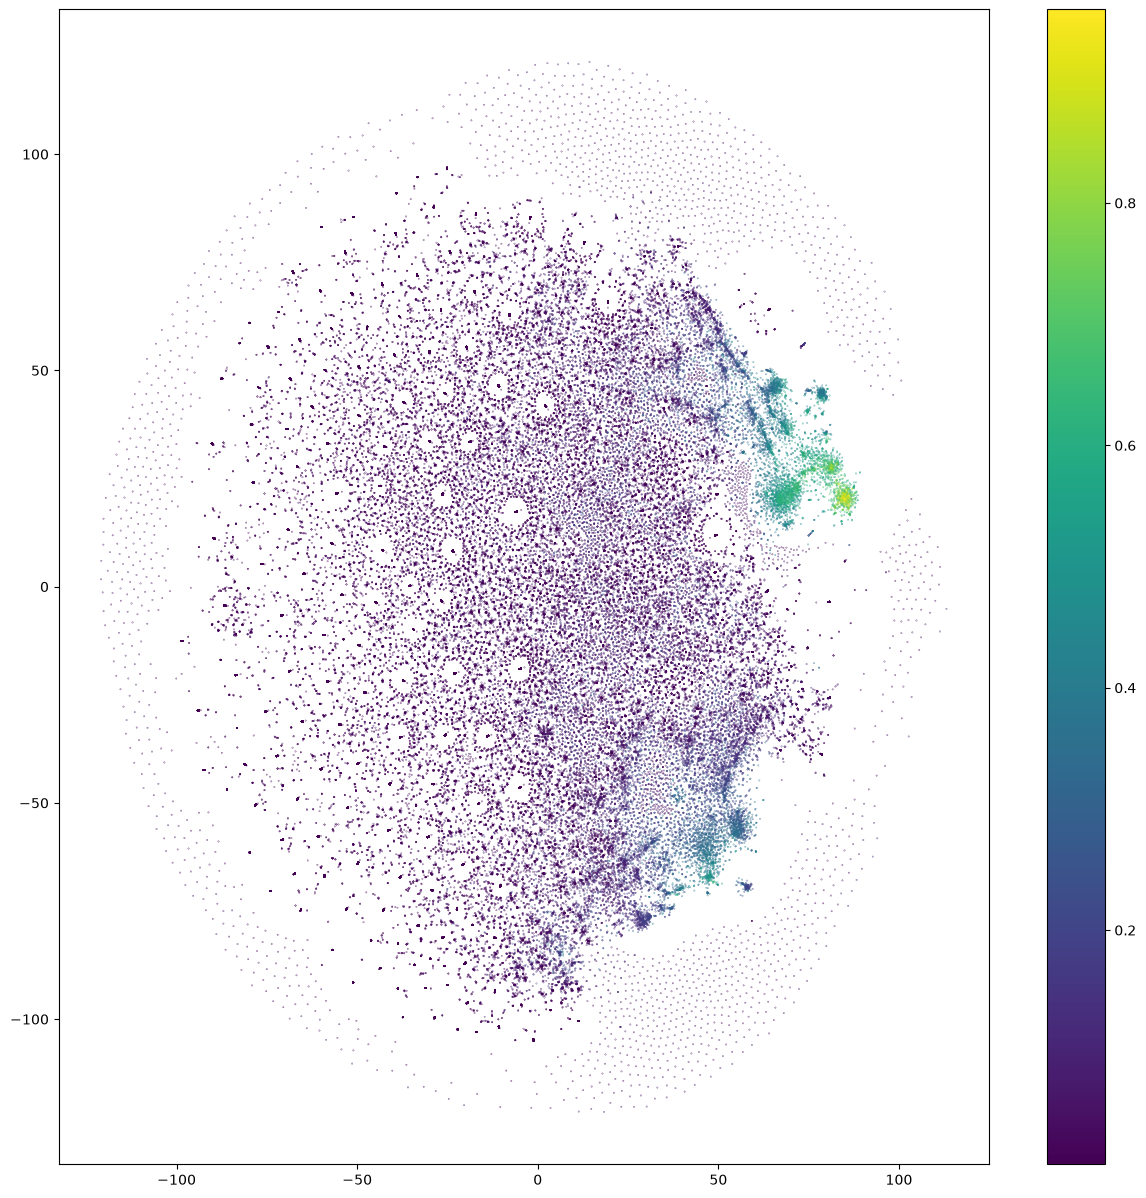

In [32]:
plt.figure(figsize=(15,15))

plt.scatter(user_proj[:, 0], user_proj[:, 1], c = open_rates,s=0.05)
plt.colorbar()
plt.show()

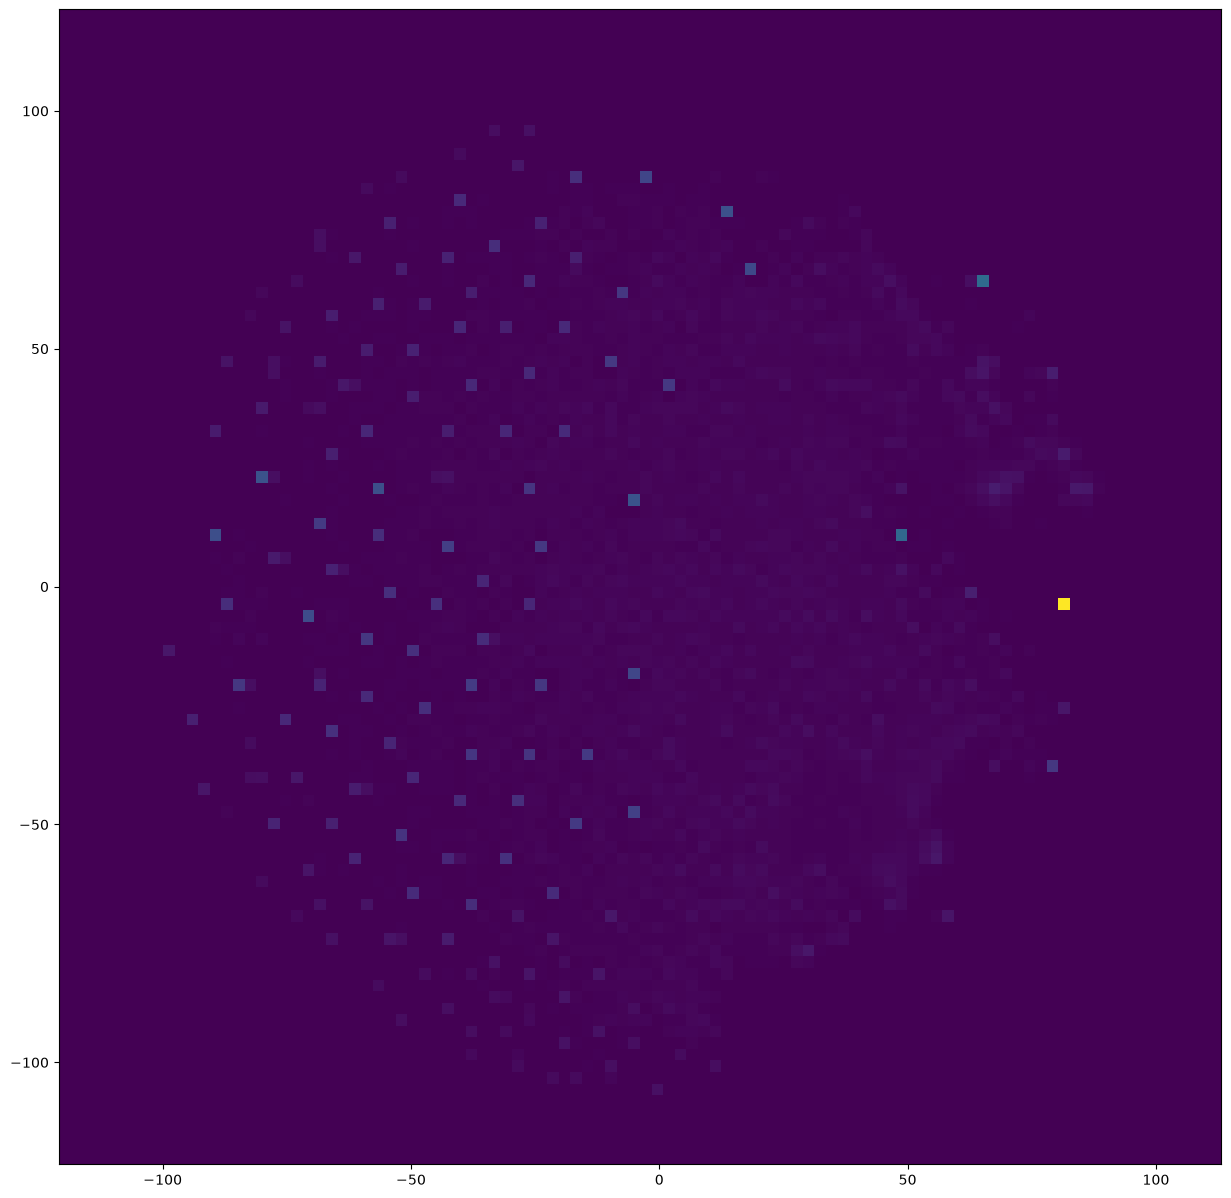

In [20]:
plt.figure(figsize=(15,15))

plt.hist2d(user_proj[:, 0], user_proj[:, 1], bins = (100, 100))
plt.show()

In [21]:
umap = umap.UMAP(n_components=2, random_state=42)

In [22]:
users_umap = umap.fit_transform(X.T)

/home/tim4ik/main_code_base/python_projects/Active-Learning-for-Email-Interaction-Dynamics/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


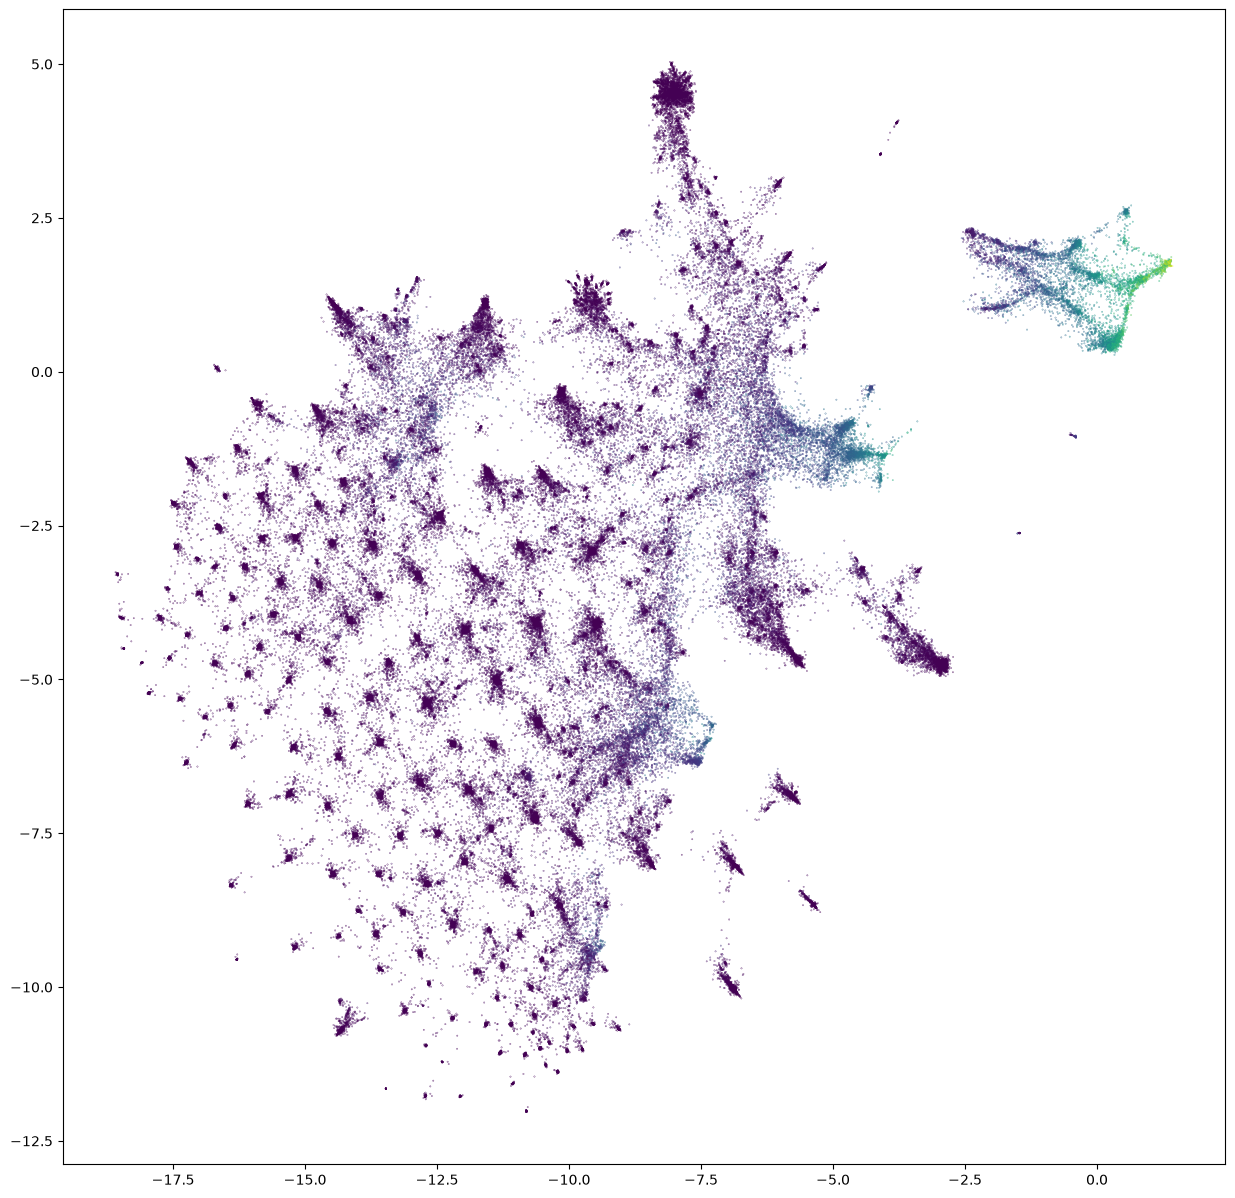

In [33]:
plt.figure(figsize=(15,15))

plt.scatter(users_umap[:, 0], users_umap[:, 1], s=0.05 ,c = open_rates)
plt.show()

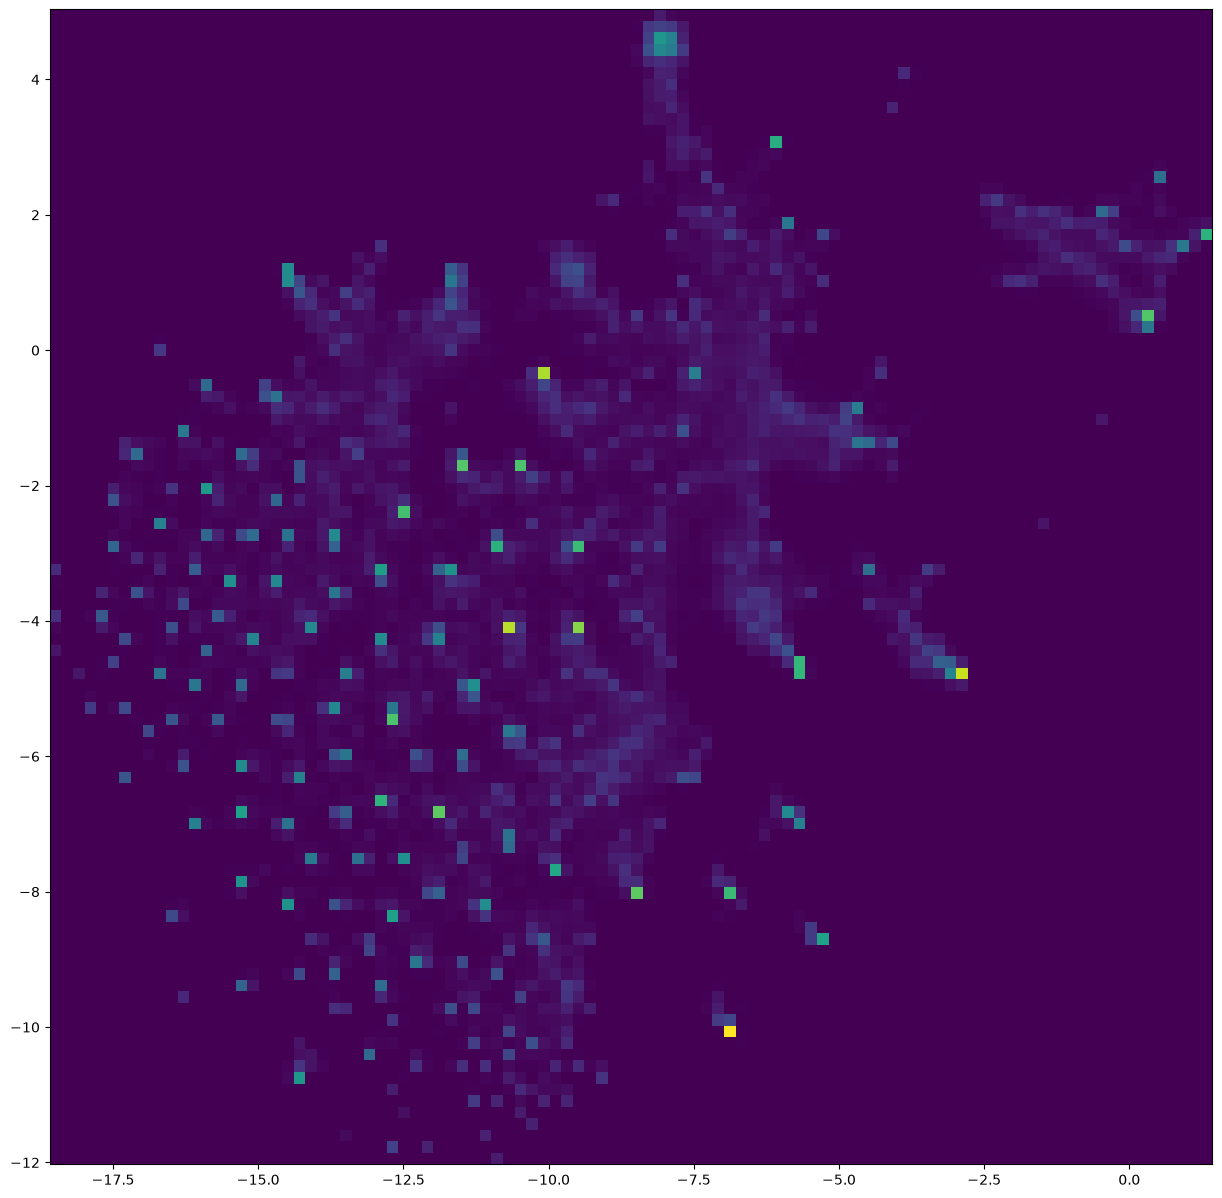

In [34]:
plt.figure(figsize=(15,15))

plt.hist2d(users_umap[:, 0], users_umap[:, 1], bins = (100, 100))
plt.show()

In [38]:
pca = PCA(n_components=2)

In [40]:
users_pca = pca.fit_transform(X.T)

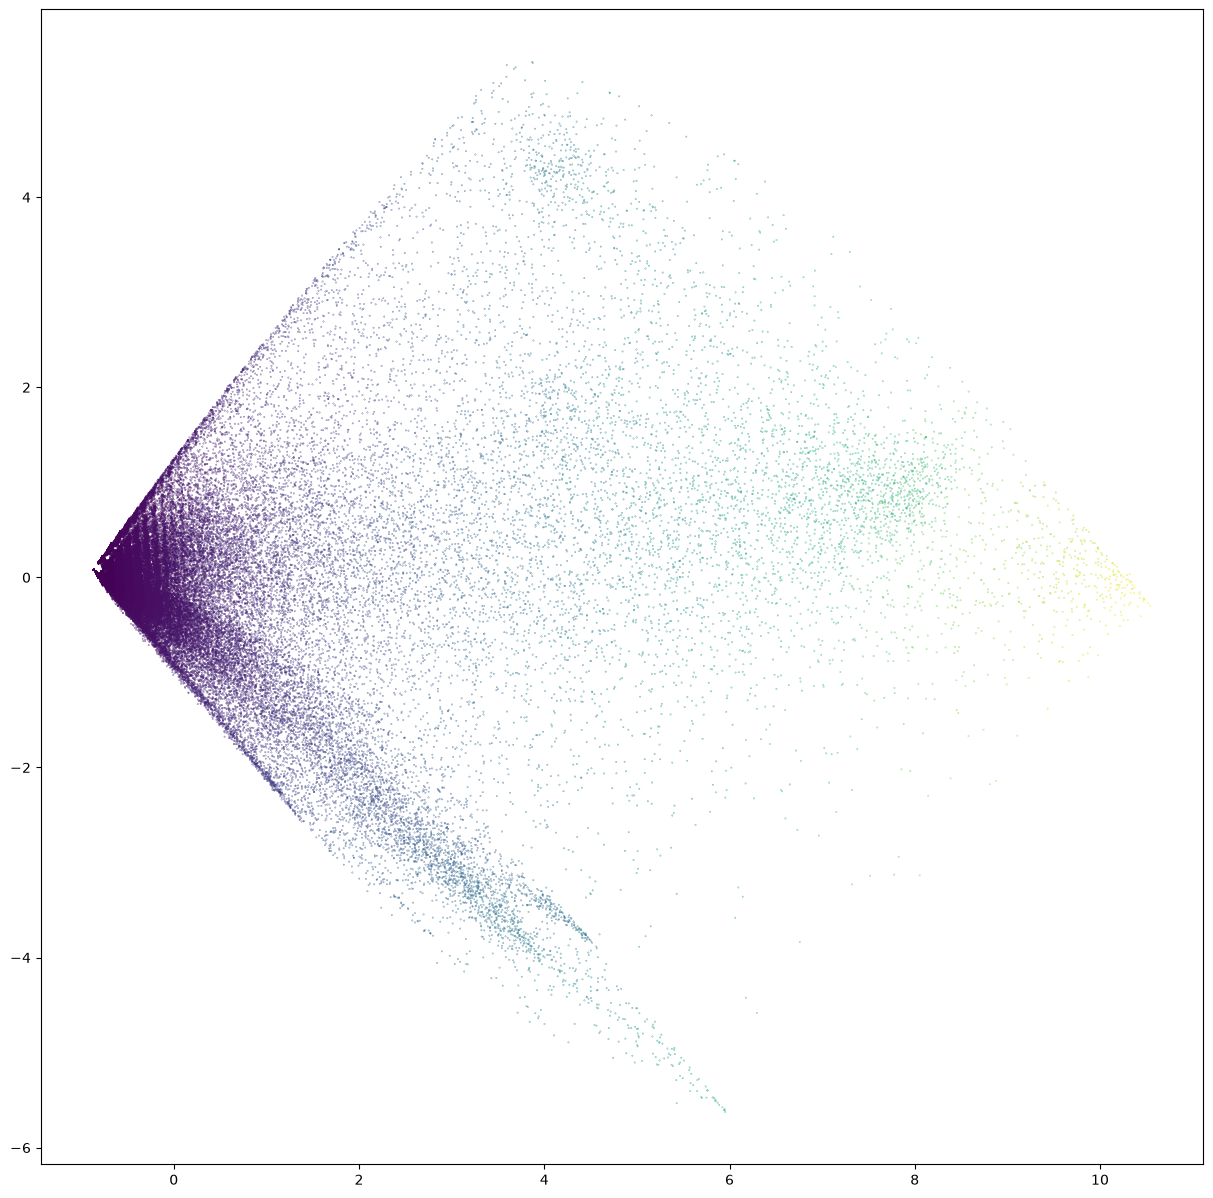

In [42]:
plt.figure(figsize=(15,15))

plt.scatter(users_pca[:, 0], users_pca[:, 1], s=0.05 ,c = open_rates)
plt.show()

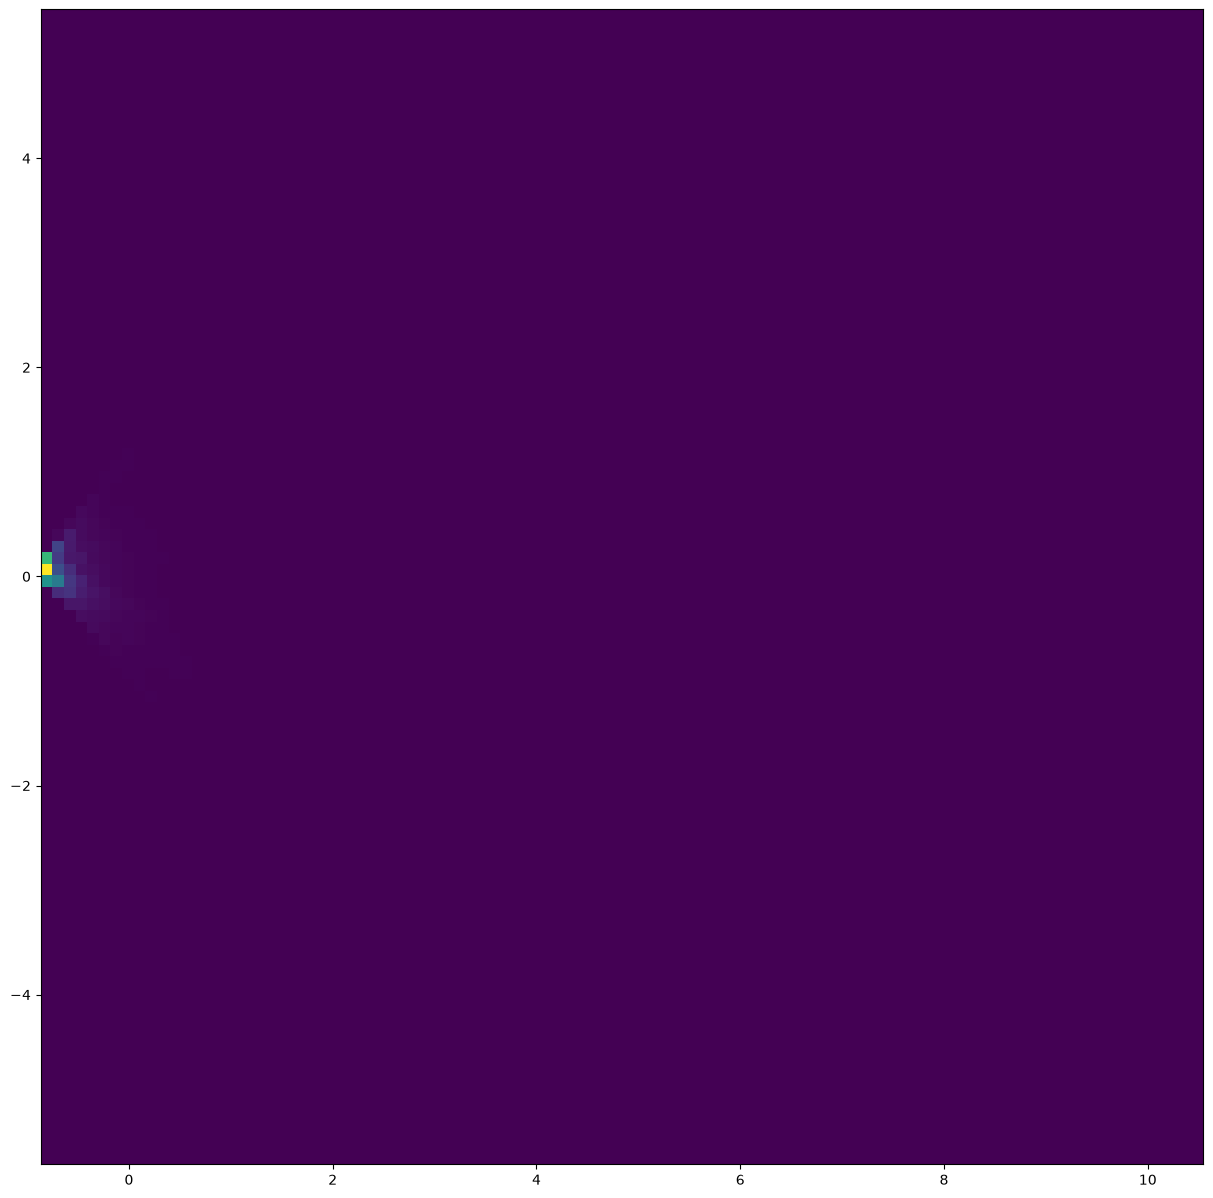

In [41]:
plt.figure(figsize=(15,15))

plt.hist2d(users_pca[:, 0], users_pca[:, 1], bins = (100, 100))
plt.show()